# Árvore, floresta ou boosting? Detecção de intrusões no NSL-KDD

Notebook do experimento do artigo. Compara **Árvore de Decisão**, **Random Forest** e **XGBoost** na mesma base, com a mesma divisão treino/teste e semente fixa.

**Tarefa:** classificar cada conexão de rede como `normal` (0) ou `ataque` (1).

**Regras que seguimos (e que o enunciado cobra):**
1. Os três modelos usam a mesma divisão e o mesmo orçamento de ajuste (mesmo `n_iter` e mesma validação cruzada).
2. O conjunto de teste **nunca** é usado para ajustar nada: o ajuste usa validação cruzada só no treino.
3. Métricas além da acurácia: precisão, recall, F1 e matriz de confusão, mais tempos e interpretabilidade.

Dados: NSL-KDD (Tavallaee et al., 2009), uso acadêmico. Cite a fonte e a licença no artigo.

## 1. Configuração e versões

In [1]:
# Instale uma vez, se precisar:  pip install -r requirements.txt
import os, time, warnings, urllib.request, urllib.parse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
for p in ["data", "figures", "results"]:
    Path(p).mkdir(exist_ok=True)

# Anote estas versões no artigo e no README
import sys
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

Python 3.14.8 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


## 2. Dados

O NSL-KDD tem 41 atributos por conexão (duração, protocolo, serviço, bytes, taxas de erro...), o rótulo (`normal` ou o nome do ataque) e uma coluna de dificuldade que descartamos.

Usamos este dataset para a realização do nosso trabalho: https://www.kaggle.com/datasets/hassan06/nslkdd

Usamos a divisão **oficial**: `KDDTrain+` para treinar e `KDDTest+` para testar. Atenção: o teste oficial contém ataques que **não aparecem no treino**. Por isso os números costumam ser menores do que em divisões aleatórias, e isso é uma boa discussão para a seção de limitações.

Os arquivos **não vão para o repositório**: o código baixa na primeira execução. Se o download falhar (rede bloqueada ou link fora do ar), baixe `KDDTrain+.txt` e `KDDTest+.txt` de outro espelho (por exemplo, Kaggle ou UNB) e coloque na pasta `data/`.

In [ ]:
COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment",
        "urgent","hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted",
        "num_root","num_file_creations","num_shells","num_access_files","num_outbound_cmds",
        "is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
        "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate",
        "dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
        "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
        "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
        "label","difficulty"]
BASE_URL = ""

def carregar(nome):
    caminho = Path('./data/' + nome)
    """
    if not caminho.exists():
        url = BASE_URL + urllib.parse.quote(nome)
        print("Baixando", url)
        urllib.request.urlretrieve(url, caminho)
    """
    return pd.read_csv(caminho, header=None, names=COLS)

treino = carregar("KDDTrain+.txt")
teste  = carregar("KDDTest+.txt")
print("treino:", treino.shape, "| teste:", teste.shape)
treino.head()

treino: (125973, 43) | teste: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


### 2.1 Exploração rápida

Antes de modelar, olhamos o balanceamento das classes. Se uma classe for rara, a acurácia engana.

        treino  teste
label                
normal   0.535  0.431
ataque   0.465  0.569

Rótulos só no teste: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


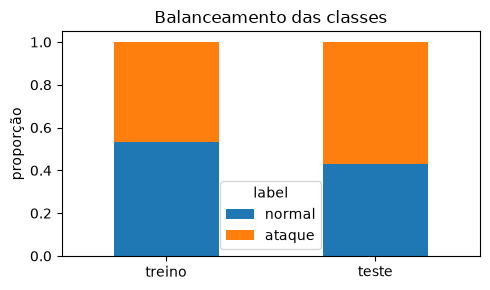

In [4]:
def para_binario(df):
    X = df.drop(columns=["label", "difficulty"])
    y = (df["label"] != "normal").astype(int)      # 0 = normal, 1 = ataque
    return X, y

X_train, y_train = para_binario(treino)
X_test,  y_test  = para_binario(teste)

dist = pd.DataFrame({"treino": y_train.value_counts(normalize=True),
                     "teste":  y_test.value_counts(normalize=True)}).rename(index={0: "normal", 1: "ataque"})
print(dist.round(3))

# Tipos de ataque presentes em cada conjunto (note os que só existem no teste)
so_no_teste = sorted(set(teste.label) - set(treino.label))
print("\nRótulos só no teste:", so_no_teste)

fig, ax = plt.subplots(figsize=(5, 3))
dist.T.plot(kind="bar", stacked=True, ax=ax, rot=0)
ax.set_ylabel("proporção"); ax.set_title("Balanceamento das classes")
plt.tight_layout(); plt.savefig("figures/balanceamento.png", dpi=150); plt.show()

## 3. Pré-processamento

Três colunas são texto (`protocol_type`, `service`, `flag`). Convertemos em colunas 0/1 com *one-hot encoding*. Árvores não precisam de normalização, então as demais colunas passam direto.

Tudo fica dentro de um `Pipeline`: assim, durante a validação cruzada, o encoder é ajustado **só com as dobras de treino**, sem vazamento. `handle_unknown="ignore"` evita erro quando o teste traz um serviço que o treino não tinha.

In [5]:
CAT = ["protocol_type", "service", "flag"]
preprocessor = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
    remainder="passthrough", verbose_feature_names_out=False)

def make_pipe(clf):
    return Pipeline([("prep", clone(preprocessor)), ("clf", clf)])

# Validação interna para as demonstrações didáticas (seções 5 a 7), tirada SÓ do treino
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
prep_demo = clone(preprocessor).fit(X_tr)
Xtr_t, Xval_t = prep_demo.transform(X_tr), prep_demo.transform(X_val)
nomes = prep_demo.get_feature_names_out()
print("atributos após one-hot:", len(nomes))

atributos após one-hot: 121


## 4. Os três modelos com ajuste comparável

Cada modelo recebe **o mesmo esforço**: `RandomizedSearchCV` com 10 combinações sorteadas, validação cruzada estratificada de 3 dobras e `scoring="f1"` (F1 da classe *ataque*). O conjunto de teste não aparece aqui.

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
N_ITER = 10

espacos = {
    "Árvore": (DecisionTreeClassifier(random_state=SEED),
               {"clf__max_depth": [3, 5, 8, 12, 20, None],
                "clf__min_samples_leaf": [1, 5, 20, 50],
                "clf__criterion": ["gini", "entropy"]}),
    "XGBoost": (XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss"),
               {"clf__n_estimators": [100, 200, 300],
                "clf__learning_rate": [0.03, 0.1, 0.3],
                "clf__max_depth": [3, 6, 9],
                "clf__subsample": [0.7, 1.0]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1), # o mais lento, nós decidimos colocar essa técnica por ultimo
               {"clf__n_estimators": [100, 200, 300],
                "clf__max_depth": [8, 16, 24, None],
                "clf__max_features": ["sqrt", 0.3, 0.5]}),
}

melhores, info_busca = {}, {}
for nome, (clf, grade) in espacos.items():
    busca = RandomizedSearchCV(make_pipe(clf), grade, n_iter=N_ITER, cv=cv,
                               scoring="f1", random_state=SEED, refit=True)
    t0 = time.perf_counter()
    busca.fit(X_train, y_train)
    info_busca[nome] = {"tempo_busca_s": time.perf_counter() - t0,
                        "treino_final_s": busca.refit_time_,
                        "f1_cv": busca.best_score_,
                        "params": {k.replace("clf__", ""): v for k, v in busca.best_params_.items()}}
    melhores[nome] = busca.best_estimator_
    print(f"{nome:14s} F1(cv)={busca.best_score_:.4f}  {info_busca[nome]['params']}")

Árvore         F1(cv)=0.9983  {'min_samples_leaf': 1, 'max_depth': 20, 'criterion': 'entropy'}
XGBoost        F1(cv)=0.9989  {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.3}
Random Forest  F1(cv)=0.9989  {'n_estimators': 300, 'max_features': 0.5, 'max_depth': 24}


## 5. Avaliação no teste

Aqui, e só aqui, olhamos o conjunto de teste. Medimos:
- **Precisão:** dos que o modelo chamou de ataque, quantos eram ataque (mede alarmes falsos).
- **Recall:** dos ataques reais, quantos o modelo pegou (mede ataques que passam).
- **F1:** equilíbrio entre os dois.
- **Tempo de predição** em milissegundos por 1000 conexões (média de 5 execuções).

In [8]:
def tempo_predicao_ms_por_mil(modelo, X, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); modelo.predict(X); ts.append(time.perf_counter() - t0)
    return 1000 * np.mean(ts) / len(X) * 1000

linhas, matrizes, preds = [], {}, {}
for nome, modelo in melhores.items():
    y_pred = modelo.predict(X_test)
    preds[nome] = y_pred
    matrizes[nome] = confusion_matrix(y_test, y_pred)
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Treino final (s)": info_busca[nome]["treino_final_s"],
        "Predição (ms/1000 conexões)": tempo_predicao_ms_por_mil(modelo, X_test),
    })
resultados = pd.DataFrame(linhas).set_index("Modelo")
resultados.round(4).to_csv("results/metricas.csv")
resultados.round(4)

,Acurácia,Precisão,Recall,F1,Treino final (s),Predição (ms/1000 conexões)
Modelo,,,,,,
Árvore,0.7822,0.9591,0.6448,0.7712,1.0568,1.2851
XGBoost,0.8000,0.9691,0.6700,0.7923,2.2461,2.0843
Random Forest,0.7946,0.9685,0.6607,0.7855,112.8699,7.2947


 Árvore
              precision    recall  f1-score   support

      normal     0.6725    0.9636    0.7921      9711
      ataque     0.9591    0.6448    0.7712     12833

    accuracy                         0.7822     22544
   macro avg     0.8158    0.8042    0.7817     22544
weighted avg     0.8356    0.7822    0.7802     22544

 XGBoost
              precision    recall  f1-score   support

      normal     0.6902    0.9718    0.8072      9711
      ataque     0.9691    0.6700    0.7923     12833

    accuracy                         0.8000     22544
   macro avg     0.8297    0.8209    0.7997     22544
weighted avg     0.8490    0.8000    0.7987     22544

 Random Forest
              precision    recall  f1-score   support

      normal     0.6842    0.9716    0.8030      9711
      ataque     0.9685    0.6607    0.7855     12833

    accuracy                         0.7946     22544
   macro avg     0.8264    0.8161    0.7943     22544
weighted avg     0.8460    0.7946    0.793

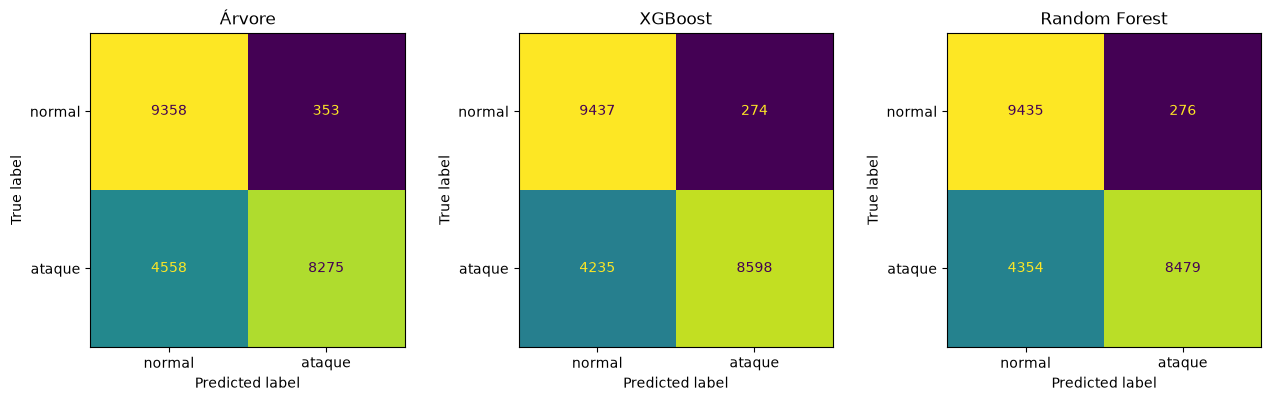

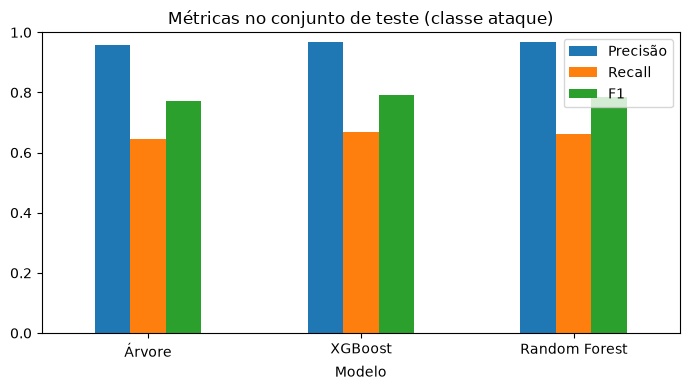

In [9]:
# Relatório completo por classe e matrizes de confusão
for nome, y_pred in preds.items():
    print("=" * 60, "\n", nome)
    print(classification_report(y_test, y_pred, target_names=["normal", "ataque"], digits=4))

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (nome, cm) in zip(axs, matrizes.items()):
    ConfusionMatrixDisplay(cm, display_labels=["normal", "ataque"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(nome)
plt.tight_layout(); plt.savefig("figures/matrizes_confusao.png", dpi=150); plt.show()

# Gráfico de métricas
ax = resultados[["Precisão", "Recall", "F1"]].plot(kind="bar", figsize=(7, 4), rot=0, ylim=(0, 1))
ax.set_title("Métricas no conjunto de teste (classe ataque)")
plt.tight_layout(); plt.savefig("figures/metricas.png", dpi=150); plt.show()

### 5.1 Custo dos erros

- **Falso negativo (FN):** ataque não detectado. Pode significar invasão bem-sucedida.
- **Falso positivo (FP):** alarme falso. Custa tempo do analista e gera fadiga de alertas.

Os pesos abaixo são **hipóteses editáveis** (aqui, um FN custa 10 vezes um FP). Justifique o valor que vocês escolherem no artigo e teste outros (1, 5, 20, 50) para ver se a recomendação muda.

In [10]:
CUSTO_FN, CUSTO_FP = 10, 1
linhas = []
for nome, cm in matrizes.items():
    tn, fp, fn, tp = cm.ravel()
    linhas.append({"Modelo": nome, "FN (ataques perdidos)": fn, "FP (alarmes falsos)": fp,
                   "Custo total": CUSTO_FN * fn + CUSTO_FP * fp})
custos = pd.DataFrame(linhas).set_index("Modelo")
custos.to_csv("results/custos.csv")
custos

,FN (ataques perdidos),FP (alarmes falsos),Custo total
Modelo,,,
Árvore,4558,353,45933
XGBoost,4235,274,42624
Random Forest,4354,276,43816


## 6. Árvore de decisão: ler as regras e ver o overfitting

**Exemplo antes da teoria:** uma árvore rasa (profundidade 3) cujas regras qualquer pessoa lê.

|--- src_bytes <= 28.50
|   |--- service_http <= 0.50
|   |   |--- dst_bytes <= 3.50
|   |   |   |--- class: 1
|   |   |--- dst_bytes >  3.50
|   |   |   |--- class: 0
|   |--- service_http >  0.50
|   |   |--- dst_host_same_srv_rate <= 0.31
|   |   |   |--- class: 1
|   |   |--- dst_host_same_srv_rate >  0.31
|   |   |   |--- class: 0
|--- src_bytes >  28.50
|   |--- service_ecr_i <= 0.50
|   |   |--- hot <= 0.50
|   |   |   |--- class: 0
|   |   |--- hot >  0.50
|   |   |   |--- class: 1
|   |--- service_ecr_i >  0.50
|   |   |--- src_bytes <= 292.00
|   |   |   |--- class: 0
|   |   |--- src_bytes >  292.00
|   |   |   |--- class: 1



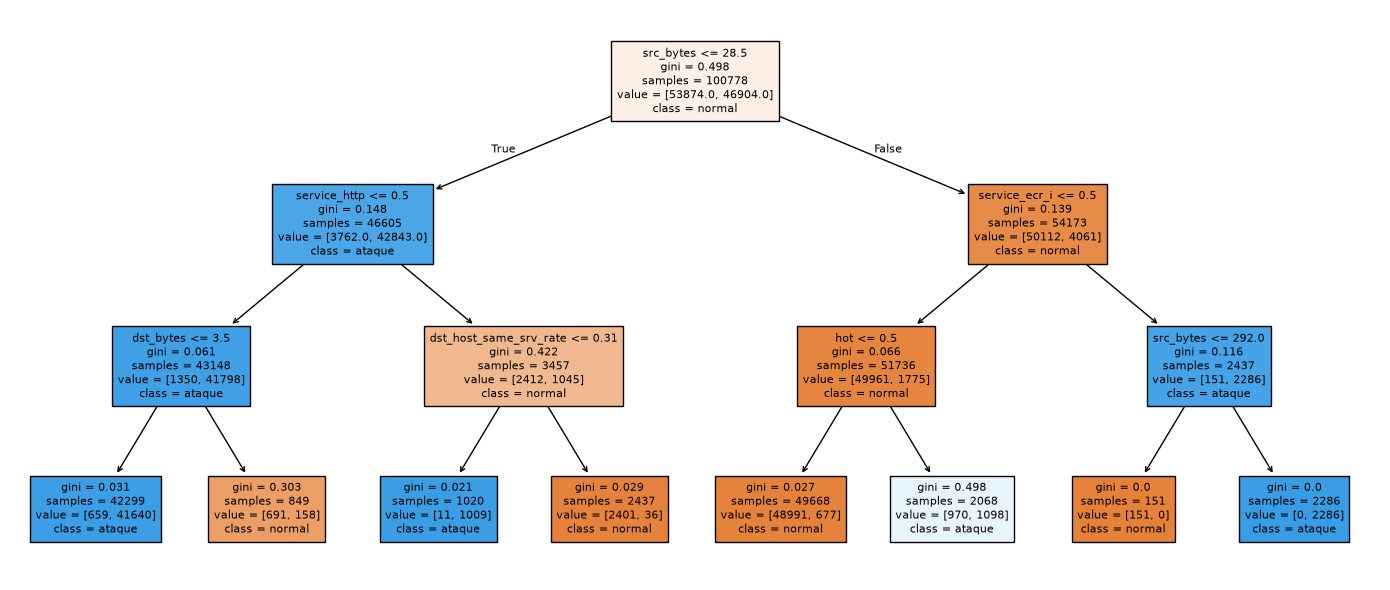

In [11]:
pequena = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(Xtr_t, y_tr)
print(export_text(pequena, feature_names=list(nomes)))

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(pequena, feature_names=nomes, class_names=["normal", "ataque"], filled=True, fontsize=8, ax=ax)
plt.tight_layout(); plt.savefig("figures/arvore_rasa.png", dpi=150); plt.show()

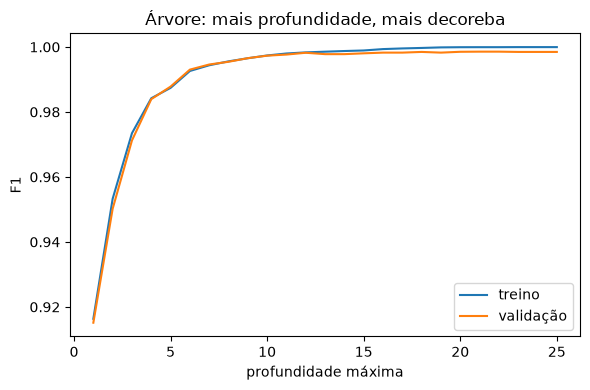

In [12]:
# Overfitting: aumentamos a profundidade e comparamos treino x validação (validação interna, sem teste)
profs = list(range(1, 26))
f1_tr, f1_val = [], []
for d in profs:
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xtr_t, y_tr)
    f1_tr.append(f1_score(y_tr, t.predict(Xtr_t)))
    f1_val.append(f1_score(y_val, t.predict(Xval_t)))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(profs, f1_tr, label="treino"); ax.plot(profs, f1_val, label="validação")
ax.set_xlabel("profundidade máxima"); ax.set_ylabel("F1"); ax.legend()
ax.set_title("Árvore: mais profundidade, mais decoreba")
plt.tight_layout(); plt.savefig("figures/overfitting_arvore.png", dpi=150); plt.show()

## 7. Random Forest: estabilidade e erro out-of-bag

Cada árvore da floresta treina numa amostra *bootstrap* (com reposição); os exemplos que ficaram de fora formam a estimativa *out-of-bag* (OOB), um teste de graça. Variamos o número de árvores e repetimos com 3 sementes para ver a **estabilidade** (a faixa sombreada é o desvio entre as sementes).

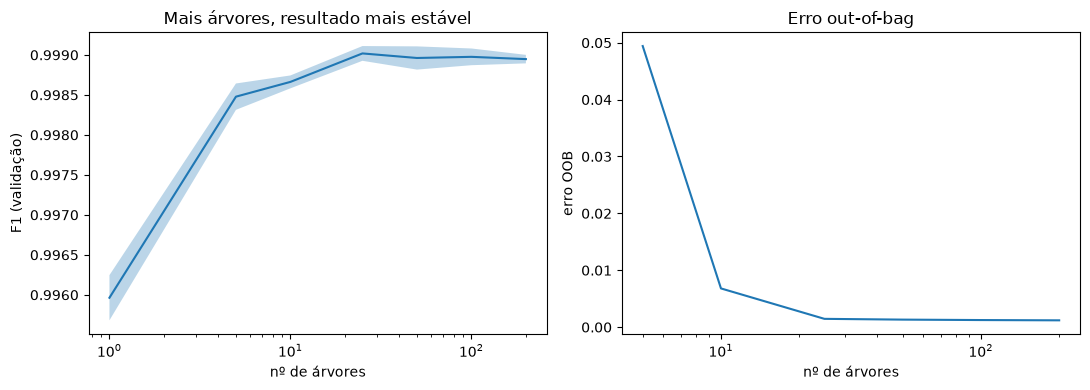

In [13]:
n_arvores = [1, 5, 10, 25, 50, 100, 200]
res_f1 = {s: [] for s in (1, 2, 3)}
res_oob = {s: [] for s in (1, 2, 3)}
for s in res_f1:
    for n in n_arvores:
        rf = RandomForestClassifier(n_estimators=n, oob_score=True, bootstrap=True,
                                    random_state=s, n_jobs=-1).fit(Xtr_t, y_tr)
        res_f1[s].append(f1_score(y_val, rf.predict(Xval_t)))
        res_oob[s].append(1 - rf.oob_score_ if n > 1 else np.nan)   # erro OOB

f1_arr = np.array(list(res_f1.values())); oob_arr = np.array(list(res_oob.values()))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(n_arvores, f1_arr.mean(0)); axs[0].fill_between(n_arvores, f1_arr.mean(0)-f1_arr.std(0), f1_arr.mean(0)+f1_arr.std(0), alpha=.3)
axs[0].set_xscale("log"); axs[0].set_xlabel("nº de árvores"); axs[0].set_ylabel("F1 (validação)"); axs[0].set_title("Mais árvores, resultado mais estável")
axs[1].plot(n_arvores, np.nanmean(oob_arr, 0)); axs[1].set_xscale("log")
axs[1].set_xlabel("nº de árvores"); axs[1].set_ylabel("erro OOB"); axs[1].set_title("Erro out-of-bag")
plt.tight_layout(); plt.savefig("figures/random_forest_estabilidade.png", dpi=150); plt.show()

## 8. XGBoost: taxa de aprendizado e parada antecipada

No boosting, cada rodada adiciona uma árvore que corrige os erros acumulados até ali. A **taxa de aprendizado** controla o tamanho de cada passo. Com *early stopping*, o treino para quando a perda de validação deixa de melhorar por 20 rodadas seguidas, o que protege contra overfitting. A validação é a mesma interna da seção 3 (nada do teste).

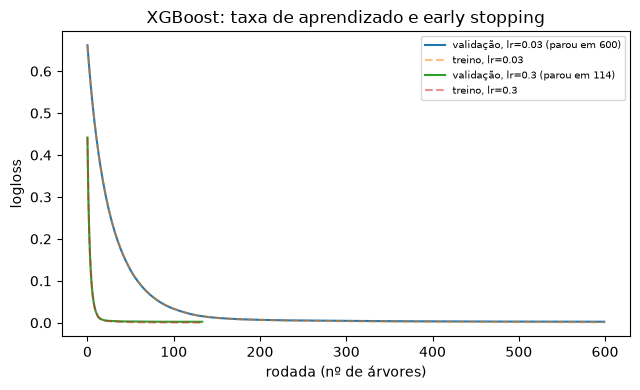

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for lr in (0.03, 0.3):
    xgb = XGBClassifier(n_estimators=600, learning_rate=lr, max_depth=6, random_state=SEED,
                        n_jobs=-1, eval_metric="logloss", early_stopping_rounds=20)
    xgb.fit(Xtr_t, y_tr, eval_set=[(Xtr_t, y_tr), (Xval_t, y_val)], verbose=False)
    h = xgb.evals_result()
    ax.plot(h["validation_1"]["logloss"], label=f"validação, lr={lr} (parou em {xgb.best_iteration + 1})")
    ax.plot(h["validation_0"]["logloss"], "--", alpha=.5, label=f"treino, lr={lr}")
ax.set_xlabel("rodada (nº de árvores)"); ax.set_ylabel("logloss"); ax.legend(fontsize=7)
ax.set_title("XGBoost: taxa de aprendizado e early stopping")
plt.tight_layout(); plt.savefig("figures/xgboost_early_stopping.png", dpi=150); plt.show()

## 9. Interpretabilidade: o que mais pesa na decisão

Importância de atributos dos **modelos finais** (os melhores da busca). Para o XGBoost, a importância padrão é por ganho médio de divisão. Para uma explicação por previsão, vale citar o SHAP como extensão (ver referências do enunciado).

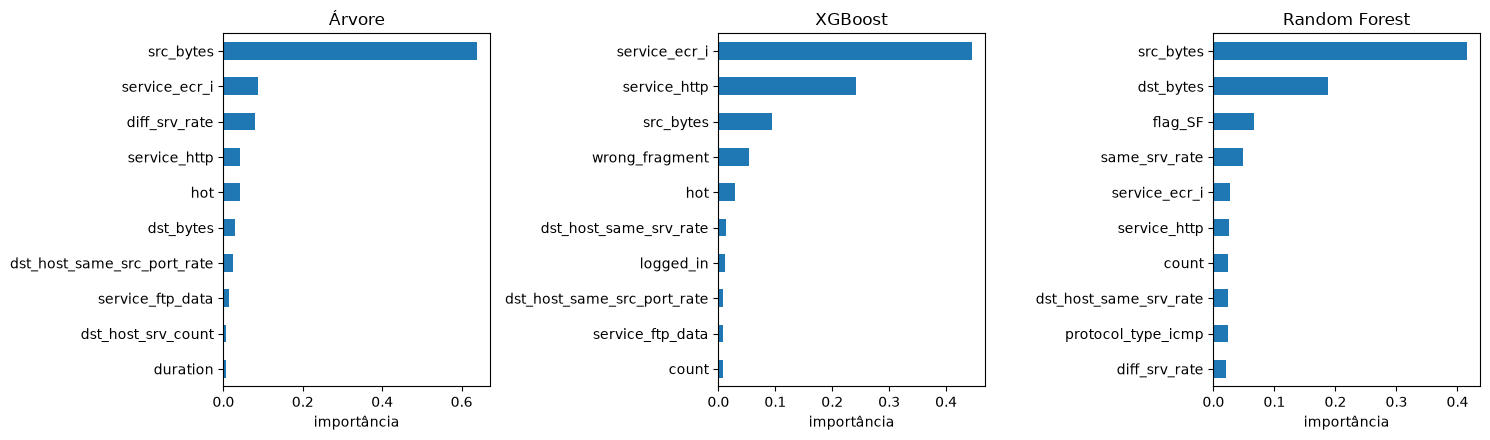

,Árvore,XGBoost,Random Forest
0,src_bytes,service_ecr_i,src_bytes
1,service_ecr_i,service_http,dst_bytes
2,diff_srv_rate,src_bytes,flag_SF
3,service_http,wrong_fragment,same_srv_rate
4,hot,hot,service_ecr_i
5,dst_bytes,dst_host_same_srv_rate,service_http
6,dst_host_same_src_port_rate,logged_in,count
7,service_ftp_data,dst_host_same_src_port_rate,dst_host_same_srv_rate
8,dst_host_srv_count,service_ftp_data,protocol_type_icmp
9,duration,count,diff_srv_rate


In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
tabela_imp = {}
for ax, (nome, modelo) in zip(axs, melhores.items()):
    nomes_f = modelo.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(modelo.named_steps["clf"].feature_importances_, index=nomes_f).sort_values(ascending=False)
    tabela_imp[nome] = imp.head(10)
    imp.head(10)[::-1].plot(kind="barh", ax=ax); ax.set_title(nome); ax.set_xlabel("importância")
plt.tight_layout(); plt.savefig("figures/importancias.png", dpi=150); plt.show()
pd.DataFrame({k: v.index for k, v in tabela_imp.items()})

## 10. Resumo para o artigo

Junte tudo em uma tabela e use os números **reais** na seção de resultados e na recomendação. Guarde também a divisão dos dados e os hiperparâmetros escolhidos.

In [16]:
resumo = resultados.round(4).join(custos[["FN (ataques perdidos)", "FP (alarmes falsos)", "Custo total"]])
resumo["Hiperparâmetros"] = [info_busca[m]["params"] for m in resumo.index]
resumo.to_csv("results/resumo.csv")
print(f"Divisão: treino oficial KDDTrain+ ({len(X_train)} conexões) / teste oficial KDDTest+ ({len(X_test)}); semente {SEED}")
resumo

Divisão: treino oficial KDDTrain+ (125973 conexões) / teste oficial KDDTest+ (22544); semente 42


,Acurácia,Precisão,Recall,F1,Treino final (s),Predição (ms/1000 conexões),FN (ataques perdidos),FP (alarmes falsos),Custo total,Hiperparâmetros
Modelo,,,,,,,,,,
Árvore,0.7822,0.9591,0.6448,0.7712,1.0568,1.2851,4558,353,45933,"{'min_samples_leaf': 1, 'max_depth': 20, 'crit..."
XGBoost,0.8000,0.9691,0.6700,0.7923,2.2461,2.0843,4235,274,42624,"{'subsample': 0.7, 'n_estimators': 200, 'max_d..."
Random Forest,0.7946,0.9685,0.6607,0.7855,112.8699,7.2947,4354,276,43816,"{'n_estimators': 300, 'max_features': 0.5, 'ma..."
